# Logistic Regression Implementation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r'C:\Users\matti\OneDrive\Desktop\Python_statistic\iris.csv')

## Initial Analysis

The Iris dataset describes flower measurements and one target variable representing the species. 

It is commonly used to demonstrate classification algorithms. 

In this example, Logistic Regression is used to classify flowers into three species: Setosa, Versicolor and Virginica.

In [3]:
df.shape

(150, 5)

The df.shape attribute returns the dimensions of the dataset as a tuple, representing the number of rows and columns. 

In this case, the output (150, 5) indicates that the Iris dataset contains 150 observations and five columns.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


The df.info() method provides an overview of the dataset structure, including the number of entries, column names, data types and non-null values. 

The output confirms that the Iris dataset contains 150 observations and five columns. The four measurement features are stored as float64, meaning they contain numerical values, while the species column is stored as an object because it contains categorical labels. All five columns have 150 non-null values,

In [ ]:
df['species'].unique()

array(['setosa', 'versicolor', 'virginica'], dtype=object)

The df['species'].unique() method identifies all the distinct values present in the species column. The output confirms that the dataset contains three flower species: Setosa, Versicolor and Virginica.

## Feature Selection

In [ ]:
X=df.drop('species',axis=1)
y=df['species']

This code separates the dataset into the input features (X) and the target variable (y) in preparation for training the Logistic Regression model.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## Splitting DataSet

In [8]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=101)

This code splits the dataset into training and testing sets using the train_test_split() function from Scikit-learn. The parameter test_size=0.3 allocates 30% of the observations to the test set and the remaining 70% to the training set.

In [9]:
scaler=StandardScaler()

In [10]:
X_scaled_tr=scaler.fit_transform(X_train)
X_scaled_tst=scaler.transform(X_test)

This code standardises the input features using Scikit-learn's StandardScaler, which is particularly important for Logistic Regression because differences in feature scales can affect model optimisation.

In [11]:
from sklearn.model_selection import GridSearchCV

## Hyperparameters Selection

In [ ]:
param_grid = {'C':[0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
              'penalty':['l1','l2'],
              'solver':['liblinear','saga']}


This code imports GridSearchCV from Scikit-learn and defines a parameter grid to identify the best hyperparameter configuration for the Logistic Regression model. 

The *C parameter* controls the strength of regularisation: smaller values apply stronger regularisation, while larger values apply weaker regularisation. 

The *penalty* parameter specifies the type of regularisation, with l1 encouraging sparse coefficients and l2 penalising large coefficients. 

The *solver* parameter determines the optimisation algorithm used to train the model. In this example, liblinear and saga are considered because they support both L1 and L2 regularisation.

The param_grid dictionary contains eight possible values for C, two regularisation types and two solvers, resulting in 32 possible hyperparameter combinations. 

These combinations will subsequently be evaluated using GridSearchCV to identify the configuration that achieves the best performance according to the selected evaluation metric. 

This process helps optimise the model systematically rather than relying on manually selected hyperparameters.

In [13]:
from sklearn.linear_model import LogisticRegression

## Model Implementation

In [14]:

log = LogisticRegression(multi_class='multinomial',max_iter=5000)

This code initialises the Logistic Regression model and uses GridSearchCV to identify the best hyperparameter configuration. The LogisticRegression() estimator is configured with multi_class='multinomial' to model the three Iris species as a multiclass classification problem, while max_iter=5000 increases the maximum number of iterations available for the optimisation process to converge.

In [15]:

grid=GridSearchCV(log,param_grid,cv=5,scoring='accuracy',n_jobs=1)

The GridSearchCV() function receives the model and the previously defined param_grid, which contains 32 possible hyperparameter combinations. 

The parameter cv=5 specifies five-fold cross-validation, meaning that each combination is evaluated across five different training and validation splits. 

The scoring='accuracy' parameter selects accuracy as the evaluation metric, measuring the proportion of correctly classified observations. 

The parameter n_jobs=1 instructs Scikit-learn to execute the computations using a single CPU process.

In [16]:
grid.fit(X_scaled_tr, y_train)

C:\Users\matti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\matti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\matti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in versio

GridSearchCV(cv=5,
             estimator=LogisticRegression(max_iter=5000,
                                          multi_class='multinomial'),
             n_jobs=1,
             param_grid={'C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
                         'penalty': ['l1', 'l2'],
                         'solver': ['liblinear', 'saga']},
             scoring='accuracy')

Finally, grid.fit(X_scaled_tr, y_train) runs the search using the standardised training features and their corresponding species labels.

In [17]:

print(grid.best_params_)

{'C': 1, 'penalty': 'l1', 'solver': 'saga'}


The output of grid.best_params_ identifies the hyperparameter combination that achieved the highest mean cross-validation accuracy during the grid search: C=1, penalty='l1' and solver='saga'. 

This indicates that, among the configurations tested, the model performed best with a regularisation strength of 1, L1 regularisation and the SAGA optimisation algorithm.

The next step creates a new Logistic Regression model using these selected hyperparameters.

In [18]:
log_model=LogisticRegression(multi_class='multinomial',max_iter=5000,C=1,penalty='l1',solver='saga')

In [19]:
log_model.fit(X_scaled_tr,y_train)

C:\Users\matti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(C=1, max_iter=5000, multi_class='multinomial', penalty='l1',
                   solver='saga')

In [20]:
prediction=log_model.predict(X_scaled_tst)
prediction

array(['setosa', 'setosa', 'setosa', 'virginica', 'versicolor',
       'virginica', 'versicolor', 'versicolor', 'virginica', 'setosa',
       'virginica', 'setosa', 'setosa', 'virginica', 'virginica',
       'versicolor', 'versicolor', 'versicolor', 'setosa', 'versicolor',
       'versicolor', 'setosa', 'versicolor', 'versicolor', 'versicolor',
       'versicolor', 'versicolor', 'virginica', 'setosa', 'setosa',
       'virginica', 'versicolor', 'virginica', 'versicolor', 'virginica',
       'versicolor', 'versicolor', 'versicolor', 'versicolor',
       'virginica', 'setosa', 'setosa', 'setosa', 'virginica',
       'versicolor'], dtype=object)

In [21]:
log_model.score(X_scaled_tst,y_test)

0.9555555555555556

The log_model.score(X_scaled_tst, y_test) method evaluates the trained Logistic Regression model on the test set by calculating its classification accuracy.

For a Logistic Regression classifier, the score() method returns the proportion of correctly classified observations.

## Results

The Logistic Regression model achieved a test accuracy of 95.56%, meaning that it correctly classified 43 out of the 45 observations in the test set, while misclassifying only two flowers.

In [22]:
from sklearn.metrics import classification_report,confusion_matrix

In [23]:
print(classification_report(y_test,prediction))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       0.95      0.95      0.95        20
   virginica       0.92      0.92      0.92        12

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



The classification_report() function provides a detailed evaluation of the Logistic Regression model by calculating precision, recall, F1-score and support for each Iris species.

## Results

The results show an overall accuracy of approximately 96%, confirming that the model correctly classified 43 out of 45 observations in the test set.

Setosa achieved perfect scores of 1.00 for precision, recall and F1-score, indicating that this species was classified correctly in every case.

Versicolor achieved scores of 0.95 across all three metrics, while Virginica achieved scores of 0.92, suggesting slightly more difficulty distinguishing this species from the others.

In [24]:
confusion_matrix(y_test,prediction)

array([[13,  0,  0],
       [ 0, 19,  1],
       [ 0,  1, 11]])

The confusion matrix provides a detailed view of the Logistic Regression model's classification results by comparing the actual Iris species with the predicted species. The rows represent the actual classes, while the columns represent the predicted classes.

The first row shows that all 13 Setosa flowers were correctly classified, with no misclassifications. In the second row, 19 out of 20 Versicolor flowers were correctly identified, while one was incorrectly classified as Virginica. Similarly, in the third row, 11 out of 12 Virginica flowers were correctly classified, while one was incorrectly identified as Versicolor.

In [25]:
cm=confusion_matrix(y_test,prediction)

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

In [27]:
unique_labels=df['species'].unique()

In [28]:
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=unique_labels)

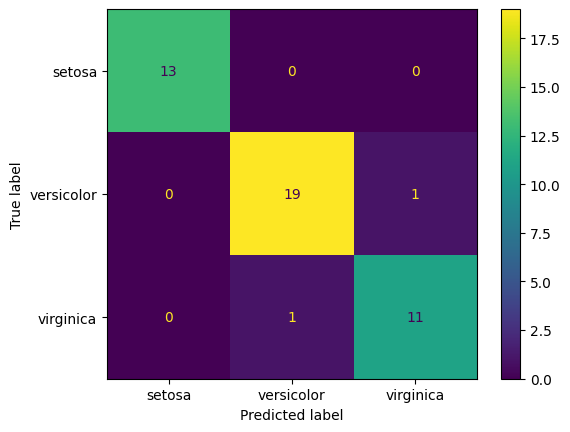

In [29]:
disp.plot();

Overall, the confusion matrix confirms that the model correctly classified 43 out of 45 observations, achieving an accuracy of approximately 95.56%.

# Key Takeaways

This practical implementation helped me understand how Logistic Regression can be applied to a multiclass classification problem using the Iris dataset. By applying StandardScaler and GridSearchCV, I learned how feature scaling and hyperparameter tuning can support model development and improve predictive performance.